# Analyse de `lambda_in` et pruning d'ordre p, sur tous les runs d'un groupe

Ce notebook est la version visuelle de `python pruning.py <runs> --mode pre`. Il utilise les mêmes fonctions de `specprune` (`load_run`, `masks_for`, `evaluate_pruned`) : pour les mêmes paramètres, il donne **les mêmes masques et les mêmes précisions** que `pruning.py`.

1. Chargement de **tous les runs** d'un dossier de `runs/` (les graines `seed*/` lancées avec `--n_runs`), et des mêmes données que l'entraînement.
2. Distribution des `lambda_in` : médiane et bande 5 à 95 % sur les runs, pour tous les filtres et canaux, et pour un filtre (`FILTER`). Puis la même chose position par position (carte ou profil temporel).
3. Dégradation du masque selon *p*, pour les trois méthodes (`gradient`, `element`, `mixte`), sur tous les filtres puis sur le filtre `FILTER`.
4. Effet de cette dégradation sur des exemples du dataset du run (ce que voit la première couche).
5. Précision sur le test du modèle élagué (pré-training) pour les trois méthodes, sur une même figure (médiane et bande 5 à 95 % sur les runs).

Seule la cellule **Paramètres** est à modifier. Les figures sont faites pour un article (style Nature Communications : pas de titre, textes en anglais, Arial 7 pt, orange, bleu, vert) et enregistrées en **PDF vectoriel et PNG 600 dpi** dans `<dossier du groupe>/analyse_lambda_in/<couche>/`. Le notebook se lance depuis `notebooks/` ; il marche pour des images (SpecCnn2D) comme pour des signaux (SpecCnn1D).

## Paramètres

In [ ]:
# Dossier dans runs/ : un groupe lancé avec --n_runs (sous-dossiers seed42/, seed43/, ...) ou un seul run.
# None = le dossier le plus récent de RUNS_ROOT. Le dataset est relu dans les runs.
GROUP_DIR = "../runs/mnist_spectral_resnet20_20261103_170107_x5"
RUNS_ROOT = "../runs"        # le notebook est dans notebooks/ : les runs sont dans ../runs

# Pruning : mêmes options que pruning.py (--p, --layers, --method, --criterion, --include_padding)
P_VALUES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
# "gradient" : par filtre, percentile sur tous les |w| du filtre (poids par poids)
# "element"  : par filtre, score d'un pixel = somme des |w| sur les canaux ; pixel retiré pour tous ses canaux
# "mixte"    : comme element, mais score sommé sur tous les filtres ; pixel retiré pour tous les filtres
METHODS = ["gradient", "element", "mixte"]
LAYERS = "trained"           # couches élaguées : "trained" (lambda_in entraîné), "*", "0", "1-5", "0,3"
CRITERION = "percentile"     # "percentile" ou "rank"
INCLUDE_PADDING = False      # True = classer aussi les positions de padding

# Ce qui est montré
LAYER = None                 # couche montrée : nom ou indice de convolution ; None = première couche élaguée
FILTER = 0                   # filtre montré seul (distribution, masque, images)
P_SHOW = [0.0, 0.3, 0.5, 0.7, 0.9]   # colonnes des figures de masques et d'images
MASK_RUN = 0                 # run des masques montrés (0 = première graine) ; None = moyenne sur les runs
EXAMPLE_INDICES = None       # indices dans le jeu de test ; None = un exemple par classe
N_EXAMPLES = 3               # nombre d'exemples si EXAMPLE_INDICES = None
IMAGE_MASK = "all"           # images : "all" (part gardée sur tous les filtres) ou "filter" (masque de FILTER)

EVALUATE = True              # précision du modèle élagué (section 5)
DEVICE = "/GPU:0"            # "/CPU:0" sans GPU

# Figures
STAT, BAND = "median", "quantile"    # médiane et bande 5-95 % ("mean" / "std" possibles)
# Distribution des lambda_in
# beaucoup de lambda_in sont nuls (L1) : un pic en 0 écrase un histogramme. Par défaut, deux panneaux :
#   a : part cumulée des |lambda_in| (la part des nuls est la hauteur de la courbe en 0 ; p du pruning
#       = part des poids sous le seuil, lisible directement sur l'axe y)
#   b : densité des lambda_in non nuls, la part des nuls étant indiquée dans le panneau
HIST_KIND = "split"          # "split" (a + b), "ecdf" (a seul) ou "density" (b seul)
ZERO_TOL = 1e-3            # |lambda_in| < ZERO_TOL : compté comme nul
HIST_BINS = 40
HIST_STYLE = "line"          # densité : "line" (médiane + bande 5-95 %) ou "points" (médiane + barres)
HIST_NORMALIZE = False       # True = densité divisée par son maximum (pic = 1)
HIST_SOURCE = "runs"         # "runs" : histogramme de chaque run, puis médiane (et bande) par classe
                             # "median" : histogramme de la médiane des lambda_in sur les runs (élément par élément)
HIST_YSCALE = "linear"       # "linear" ou "log"
HIST_SIZE_MM = (120, 75)     # largeur, hauteur de la figure de distribution
DISPLAY_DPI = 150            # taille d'affichage dans le notebook (sans effet sur les fichiers enregistrés)
WIDTH_MM = 183               # 89 = une colonne, 183 = deux colonnes
FORMATS = ["pdf", "png"]
DPI = 600
METHOD_LABELS = {"gradient": "Gradient", "element": "Element", "mixte": "Mixed"}

## Imports et style des figures

In [2]:
import csv
import glob
import json
import os
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

# Paquet specprune : installé (pip install -e .), sinon pris dans la racine du projet, que le
# notebook soit lancé depuis notebooks/ ou depuis models_spectral/
PROJECT_DIR = next((d for d in (os.path.abspath(".."), os.path.abspath("."))
                    if os.path.exists(os.path.join(d, "specprune", "prune.py"))), None)
if PROJECT_DIR is not None and PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for name in [m for m in sys.modules if m == "specprune" or m.startswith("specprune.")]:
    del sys.modules[name]  # recharge specprune si une ancienne version était déjà importée
try:
    # mêmes fonctions que pruning.py
    from specprune.prune import assign_spectral_weights, evaluate_pruned, masks_for, select_layers
    from specprune.runs import load_run, load_run_data, spectral_layers, test_dataset, valid_positions
    from specprune.training import compile_agent, recipe_from_run
    from specprune.plotting import COLORS, KEPT_CMAP, MM, Style, save
    import specprune
except ImportError as e:
    raise ImportError(f"{e}\nspecprune introuvable ou trop ancien : ouvrir le notebook depuis "
                      "models_spectral/notebooks/, ou installer le projet (pip install -e .).") from None
print("specprune", specprune.__version__, "chargé depuis", os.path.dirname(specprune.__file__))

%config InlineBackend.figure_format = "retina"
np.set_printoptions(precision=4, suppress=True)

style = Style(width_mm=WIDTH_MM, formats=FORMATS, dpi=DPI)
LAMBDA = r"$\lambda_{in}$"
VALUE_CMAP = LinearSegmentedColormap.from_list("value", ["#ffffff", "#9ecae1", COLORS[1], "#08306b"])


def figure(height_mm, nrows=1, ncols=1, width_mm=None, **kw):
    """Figure au style de l'article (largeur WIDTH_MM, hauteur en mm)."""
    style.apply()
    plt.rcParams["mathtext.default"] = "regular"   # lambda dans la police du texte
    plt.rcParams["figure.dpi"] = DISPLAY_DPI       # affichage plus grand ; fichiers : DPI
    return plt.subplots(nrows, ncols, figsize=((width_mm or style.width_mm) * MM, height_mm * MM), **kw)


def band(ax, x, curves, color, label, marker=None):
    """Médiane (ou moyenne) des runs et bande 5-95 % (ou +- écart type), si plusieurs runs."""
    y = np.stack(curves)
    center = np.median(y, 0) if STAT == "median" else y.mean(0)
    if len(y) > 1 and BAND != "none":
        lo, hi = ((np.quantile(y, 0.05, 0), np.quantile(y, 0.95, 0)) if BAND == "quantile"
                  else (y.mean(0) - y.std(0), y.mean(0) + y.std(0)))
        ax.fill_between(x, lo, hi, color=color, alpha=0.22, lw=0)
    ax.plot(x, center, color=color, label=label, marker=marker, markeredgecolor="white",
            markeredgewidth=0.4)


def clean(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def colorbar(fig, im, axes, label):
    cb = fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, aspect=25)
    cb.set_label(label)
    cb.outline.set_linewidth(style.axis_width)
    cb.ax.tick_params(width=style.axis_width)
    return cb


def publish(fig, name):
    """Affiche la figure puis l'enregistre (PDF + PNG 600 dpi) dans OUT_DIR."""
    display(fig)
    files = save(fig, os.path.join(OUT_DIR, name), style)
    print("  ->", ", ".join(os.path.relpath(f) for f in files))

specprune 1.0.0 chargé depuis c:\Users\jketchak\Documents\DALPHAcommunity\UNAMUR\EUREKA\btwg_ml\models_spectral\models_spectral\specprune


## 1. Chargement de tous les runs du dossier

Un dossier de groupe (`--n_runs`) contient un sous-dossier par graine ; chacun est rechargé (architecture, configuration spectrale, poids de fin d'entraînement). Les runs non terminés sont ignorés. Les données sont relues une fois, avec les sous-ensembles et la normalisation des runs.

In [3]:
def run_dirs_of(folder):
    """Runs terminés d'un dossier : le dossier lui-même, ou ses sous-dossiers (graines), triés par graine."""
    if os.path.exists(os.path.join(folder, "config.json")):
        found = [folder]
    else:
        found = [d for d in glob.glob(os.path.join(folder, "*"))
                 if os.path.exists(os.path.join(d, "config.json"))]
    seed = lambda d: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", os.path.basename(d))]
    return sorted(found, key=seed)


if GROUP_DIR is None:
    candidates = [d for d in glob.glob(os.path.join(RUNS_ROOT, "*")) if os.path.isdir(d) and run_dirs_of(d)]
    if not candidates:
        raise FileNotFoundError(f"Aucun run dans {RUNS_ROOT}/ : renseigner GROUP_DIR")
    GROUP_DIR = max(candidates, key=os.path.getmtime)
GROUP_DIR = os.path.normpath(GROUP_DIR)

RUN_DIRS, skipped = [], []
for d in run_dirs_of(GROUP_DIR):
    with open(os.path.join(d, "config.json")) as f:
        done = "finished_at" in json.load(f) or not os.path.exists(os.path.join(d, "backup"))
    (RUN_DIRS if done and os.path.exists(os.path.join(d, "weights.weights.h5")) else skipped).append(d)
if not RUN_DIRS:
    raise FileNotFoundError(f"Aucun run terminé (avec ses poids) dans {GROUP_DIR}")
if skipped:
    print("Ignorés (non terminés ou sans poids) :", [os.path.basename(d) for d in skipped])

agents, configs, test_sets = [], [], []
data_cache = {}
with tf.device(DEVICE):
    for d in RUN_DIRS:
        agent, config = load_run(d)
        args = config["args"]
        # le test et la normalisation ne dépendent de la graine que si une validation est tirée du train
        key = args.get("seed") if args.get("val_split", 0) else None
        if key not in data_cache:
            data_cache[key] = load_run_data(config)
        train, val, test, info = data_cache[key]
        compile_agent(agent, recipe_from_run(args), 1)   # compilation pour l'évaluation (perte du run)
        agents.append(agent); configs.append(config); test_sets.append(test_dataset(test, info, args))

archs = {(c["args"]["arch"], c["args"]["dataset"], c["dataset"]["num_classes"]) for c in configs}
if len(archs) > 1:
    raise ValueError(f"Runs non comparables dans {GROUP_DIR} : {archs}")

args = configs[0]["args"]
SEEDS = [c["args"].get("seed") for c in configs]
RUN_NAMES = [os.path.basename(d) for d in RUN_DIRS]
x_test, y_test = test
SIGNAL = info.modality == "signal"   # signal (T, C) : SpecCnn1D ; image (H, W, C) : SpecCnn2D
C = info.input_shape[-1]
mean, std = np.array(info.mean), np.array(info.std)
class_names = info.class_names or [str(i) for i in range(info.num_classes)]

print(f"Dossier  : {GROUP_DIR}  ({len(RUN_DIRS)} runs)")
print(f"Modèle   : {args['arch']}  |  config spectrale : {os.path.basename(configs[0].get('spectral_config_file') or '')}")
print(f"Dataset  : {info.name} ({info.modality}) {info.input_shape}, {info.num_classes} classes, test = {len(x_test)}")
for name, c in zip(RUN_NAMES, configs):
    print(f"  {name:<12} graine {c['args'].get('seed')}  précision test {c.get('test_accuracy', float('nan')):.4f}")

Dossier  : ..\runs\mnist_spectral_resnet20_20261103_170107_x5  (5 runs)
Modèle   : spectral_resnet20  |  config spectrale : spectral_config.json
Dataset  : mnist (image) [28, 28, 1], 10 classes, test = 10000
  seed42       graine 42  précision test 0.9943
  seed43       graine 43  précision test 0.9942
  seed44       graine 44  précision test 0.9947
  seed45       graine 45  précision test 0.9927
  seed46       graine 46  précision test 0.9944


## 2. Distribution des `lambda_in`

Tous les `lambda_in` de la couche montrée (tous les filtres et tous les canaux, positions de padding retirées), pour chaque run ; courbe = médiane des runs, bande = quantiles 5 et 95 %. L'L1 met beaucoup de `lambda_in` à zéro : un histogramme est alors écrasé par le pic en 0. D'où deux panneaux (`HIST_KIND = "split"`) : **a**, part cumulée des |`lambda_in`| (la hauteur en 0 est la part des nuls, et l'axe y se lit comme la fraction p retirée par un seuil) ; **b**, densité des `lambda_in` non nuls (|`lambda_in`| ≥ `ZERO_TOL`), la part des nuls étant indiquée dans le panneau.

Couches élaguées : ['spec_cnn2d']
Couche montrée   : 'spec_cnn2d' (convolution 0), lambda_in (16, 1, 900), filtre 0


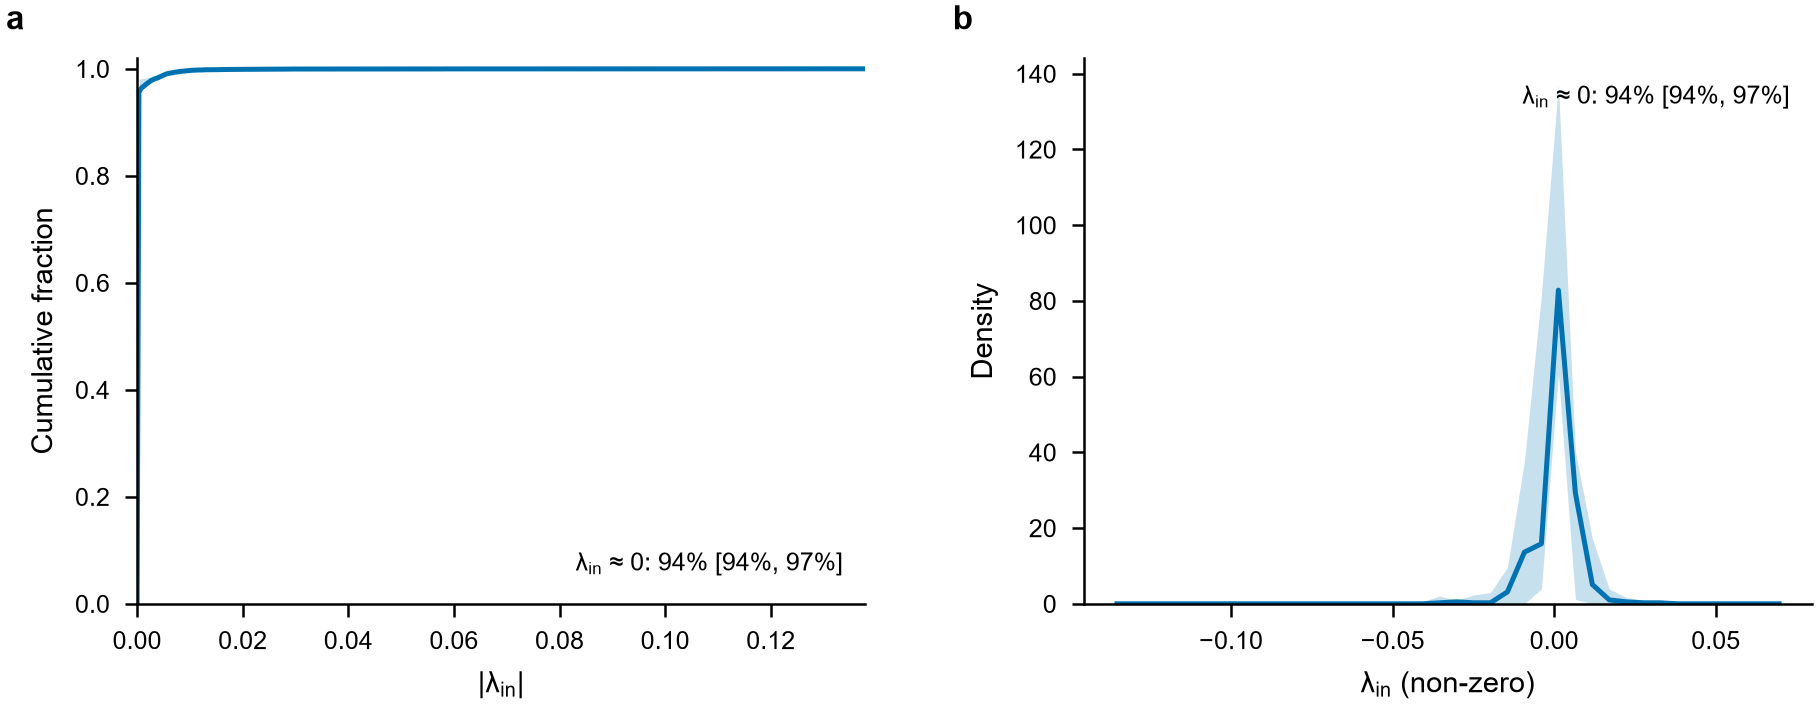

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\lambda_in_distribution.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\lambda_in_distribution.png
lambda_in nuls (|lambda_in| < 1e-06) : médiane des runs 94.2%, par run [94.2, 94.1, 94.0, 97.5, 96.9] %
tous les filtres : médiane des runs de (q5, médiane, q95) = [-0. -0.  0.] ; part |lambda_in| < 1e-3 : 96.6%
        filtre 0 : médiane des runs de (q5, médiane, q95) = [-0. -0.  0.] ; part |lambda_in| < 1e-3 : 100.0%


In [4]:
targets = select_layers(agents[0], LAYERS, "lambda_in")
spec = spectral_layers(agents[0])
# indices de convolution : les noms Keras des couches changent d'un modèle chargé à l'autre
TARGETS = [spec.index(l) for l in targets]
TARGET_NAMES = [l.name for l in targets]
if LAYER is None:
    layer = targets[0]
elif isinstance(LAYER, int):
    layer = spec[LAYER]
else:
    layer = next(l for l in spec if l.name == LAYER)
conv_index = spec.index(layer)
F, Cg = layer.lambda_in.shape[:2]
if not 0 <= FILTER < F:
    raise ValueError(f"FILTER = {FILTER} : la couche '{layer.name}' a {F} filtres (0 à {F - 1})")
print(f"Couches élaguées : {TARGET_NAMES}")
print(f"Couche montrée   : '{layer.name}' (convolution {conv_index}), lambda_in {tuple(layer.lambda_in.shape)}, filtre {FILTER}")

OUT_DIR = os.path.join(GROUP_DIR, "analyse_lambda_in", layer.name)
os.makedirs(OUT_DIR, exist_ok=True)


def to_input_grid(a, layer):
    """Tableau (..., L) sur la grille avec padding -> grille d'entrée de la couche, (..., T) ou (..., H, W)."""
    if hasattr(layer, "_L_raw"):  # SpecCnn1D
        return a[..., layer._P:layer._P + layer._L_raw]
    grid = a.reshape(a.shape[:-1] + (layer._Lh, layer._Lw))
    return grid[..., layer._Ph:layer._Ph + layer._H, layer._Pw:layer._Pw + layer._W]


# valeurs de la couche montrée dans chaque run : (runs, F, C/groups, L)
LAM = np.stack([spectral_layers(a)[conv_index].lambda_in.numpy() for a in agents])
VALID = valid_positions(layer)
# HIST_SOURCE = "median" : une seule série, la médiane des runs élément par élément (pas de bande)
SRC = np.median(LAM, axis=0, keepdims=True) if HIST_SOURCE == "median" else LAM
samples_all = [v[VALID] for v in SRC]
samples_filter = [v[FILTER][VALID[FILTER]] for v in SRC]
lo, hi = min(s.min() for s in samples_all), max(s.max() for s in samples_all)
bins = np.linspace(lo, hi + 1e-12, HIST_BINS + 1)
centers = (bins[:-1] + bins[1:]) / 2

def densities(samples):
    """Densité de chaque run (runs, classes), divisée par le maximum de la médiane si HIST_NORMALIZE."""
    d = np.stack([np.histogram(s, bins, density=True)[0] for s in samples])
    if HIST_NORMALIZE:
        d = d / max((np.median(d, 0) if STAT == "median" else d.mean(0)).max(), 1e-12)
    return np.where(d > 0, d, np.nan) if HIST_YSCALE == "log" else d   # échelle log : classes vides retirées


def points(ax, x, d, color, label, marker):
    """Médiane des runs en points, quantiles 5-95 % en barres verticales (si plusieurs runs)."""
    center = np.nanmedian(d, 0) if STAT == "median" else np.nanmean(d, 0)
    err = None
    if len(d) > 1 and BAND != "none":
        lo_, hi_ = ((np.nanquantile(d, 0.05, 0), np.nanquantile(d, 0.95, 0)) if BAND == "quantile"
                    else (center - np.nanstd(d, 0), center + np.nanstd(d, 0)))
        err = [center - lo_, hi_ - center]
    ax.errorbar(x, center, yerr=err, fmt=marker, color=color, label=label, ms=style.marker_size + 0.5,
                mec="white", mew=0.4, elinewidth=0.7, capsize=0, alpha=0.95)


# tous les lambda_in de la couche (tous les filtres et tous les canaux), un tableau par run
absval = [np.abs(s) for s in samples_all]
zero_share = np.array([np.mean(a < ZERO_TOL) for a in absval])
nonzero = [s[np.abs(s) >= ZERO_TOL] for s in samples_all]
zmed = np.median(zero_share)
zero_label = f"{LAMBDA} ≈ 0: {zmed:.0%}" + (f" [{np.quantile(zero_share, .05):.0%}, {np.quantile(zero_share, .95):.0%}]"
                                          if len(zero_share) > 1 else "")
kinds = {"split": ["ecdf", "density"], "ecdf": ["ecdf"], "density": ["density"]}[HIST_KIND]
if "density" in kinds and min(len(n) for n in nonzero) < 2:
    print("Presque tous les lambda_in sont nuls : densité des non nuls omise.")
    kinds = ["ecdf"]
if len(kinds) == 2:
    fig, axes = figure(60, 1, 2, width_mm=WIDTH_MM, gridspec_kw={"wspace": 0.3})
else:
    fig, ax = figure(HIST_SIZE_MM[1], width_mm=HIST_SIZE_MM[0])
    axes = [ax]

for letter, ax, kind in zip("ab", axes, kinds):
    if kind == "ecdf":
        # part des |lambda_in| <= x, pour chaque run, sur une grille commune
        x = np.linspace(0, max(a.max() for a in absval), 400)
        cdf = [np.searchsorted(np.sort(a), x, side="right") / a.size for a in absval]
        band(ax, x, cdf, COLORS[1], None)
        ax.set_xlabel(f"|{LAMBDA}|")
        ax.set_ylabel("Cumulative fraction")
        ax.set_xlim(0, x[-1])
        ax.set_ylim(0, 1.02)
    else:
        lo_, hi_ = min(n.min() for n in nonzero), max(n.max() for n in nonzero)
        b = np.linspace(lo_, hi_ + 1e-12, HIST_BINS + 1)
        c = (b[:-1] + b[1:]) / 2
        d = np.stack([np.histogram(n, b, density=True)[0] for n in nonzero])
        if HIST_NORMALIZE:
            d = d / max(np.median(d, 0).max(), 1e-12)
        if HIST_YSCALE == "log":
            d = np.where(d > 0, d, np.nan)
        if HIST_STYLE == "points":
            points(ax, c, d, COLORS[1], None, "o")
        else:
            band(ax, c, list(d), COLORS[1], None)
        ax.set_yscale(HIST_YSCALE)
        ax.set_xlabel(f"{LAMBDA} (non-zero)")
        ax.set_ylabel("Normalized density" if HIST_NORMALIZE else "Density")
        if HIST_YSCALE != "log":
            ax.set_ylim(0, None)
    ax.text(0.97, 0.05 if kind == "ecdf" else 0.95, zero_label, transform=ax.transAxes,
            ha="right", va="bottom" if kind == "ecdf" else "top", fontsize=style.font_size - 1)
    if len(kinds) == 2:
        ax.text(-0.18, 1.04, letter, transform=ax.transAxes, fontweight="bold",
                fontsize=style.font_size + 1, va="bottom")
publish(fig, "lambda_in_distribution")
print(f"lambda_in nuls (|lambda_in| < {ZERO_TOL:g}) : médiane des runs {zmed:.1%}, "
      f"par run {np.round(100 * zero_share, 1).tolist()} %")

for label, s in (("tous les filtres", samples_all), (f"filtre {FILTER}", samples_filter)):
    q = np.stack([np.quantile(x, [0.05, 0.5, 0.95]) for x in s])
    print(f"{label:>16} : médiane des runs de (q5, médiane, q95) = {np.median(q, 0)} ; "
          f"part |lambda_in| < 1e-3 : {np.median([np.mean(np.abs(x) < 1e-3) for x in s]):.1%}")

### Position par position

Importance d'une position d'entrée (pixel ou instant) = moyenne de |`lambda_in`| sur tous les filtres et tous les canaux. Images : médiane des runs ; signaux : médiane et bande 5 à 95 %.

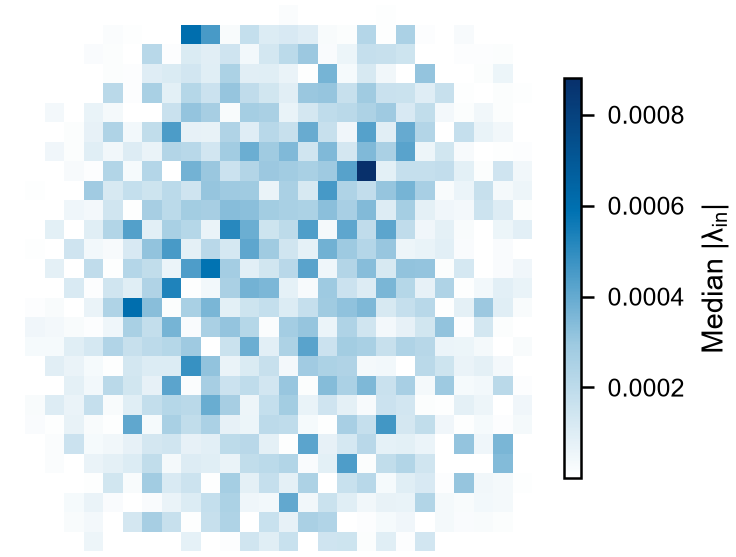

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\lambda_in_spatial.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\lambda_in_spatial.png


In [5]:
imp_all = [to_input_grid(np.abs(v), layer).mean(axis=(0, 1)) for v in LAM]       # (T,) ou (H, W)

if SIGNAL:
    fig, ax = figure(50, width_mm=WIDTH_MM)
    t = np.arange(len(imp_all[0]))
    band(ax, t, imp_all, COLORS[1], "All filters and channels")
    ax.set_xlabel("Time step")
    ax.set_ylabel(f"|{LAMBDA}|")
    ax.set_xlim(t[0], t[-1])
else:
    fig, ax = figure(60, width_mm=70)
    im = ax.imshow(np.median(imp_all, 0), cmap=VALUE_CMAP, interpolation="nearest")
    clean(ax)
    colorbar(fig, im, [ax], f"Median |{LAMBDA}|")
publish(fig, "lambda_in_spatial")

## 3. Dégradation du masque selon p, pour les trois méthodes

Masques de `pruning.py` (mêmes fonctions), calculés dans chaque run sur ses valeurs entraînées. Couleur = part des `lambda_in` gardés à chaque position d'entrée (bleu = tout gardé, orange = tout retiré). Avec `mixte`, une position est gardée ou retirée pour tous les filtres ; avec `element` et `gradient`, chaque filtre a ses propres positions, d'où une dégradation progressive sur l'ensemble des filtres. `MASK_RUN` choisit le run montré (`None` = moyenne sur les runs).

Masques montrés : seed42 ; p = [0.0, 0.3, 0.5, 0.7, 0.9]
    p |  Gradient |   Element |     Mixed   (fraction retirée, médiane des runs)
 0.00 |      0.0% |      0.0% |      0.0%
 0.10 |     10.1% |     10.1% |     10.1%
 0.20 |     20.0% |     20.0% |     20.0%
 0.30 |     30.0% |     30.0% |     30.0%
 0.40 |     40.1% |     40.1% |     40.1%
 0.50 |     50.0% |     50.0% |     50.0%
 0.60 |     59.9% |     59.9% |     59.9%
 0.70 |     70.0% |     70.0% |     70.0%
 0.80 |     80.0% |     80.0% |     80.0%
 0.90 |     89.9% |     89.9% |     89.9%
 1.00 |    100.0% |    100.0% |    100.0%


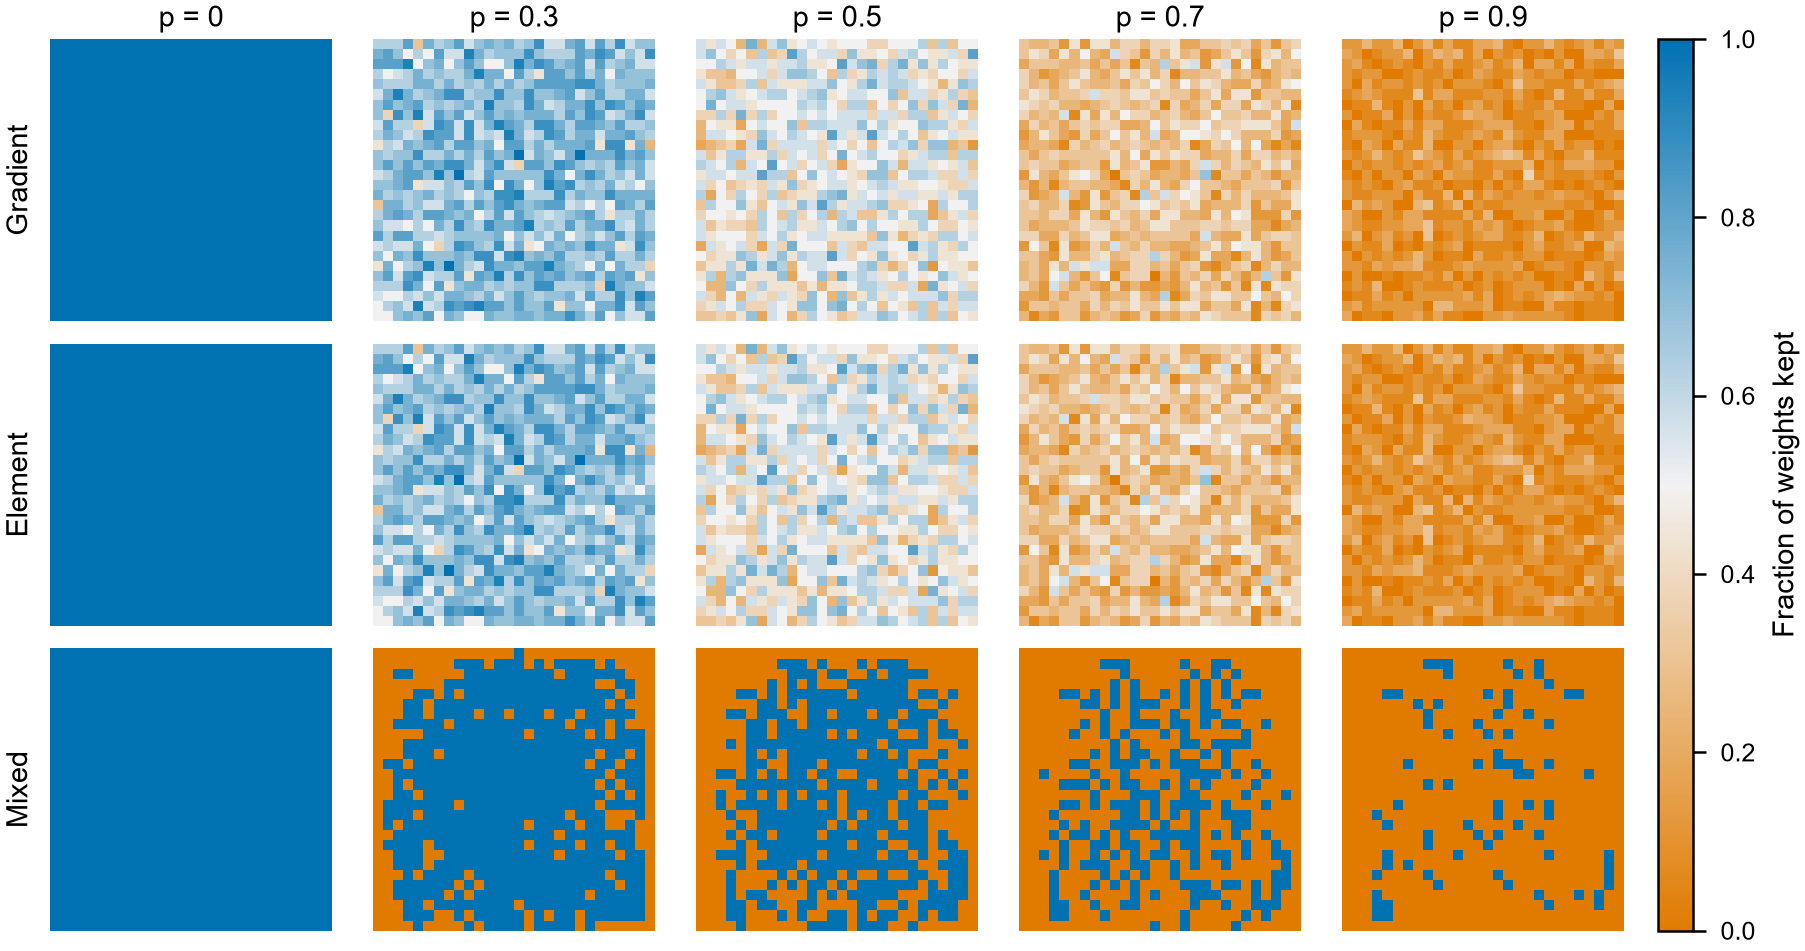

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\masks_all_filters.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\masks_all_filters.png


In [6]:
# KEPT[m][p] : part gardée par canal, (runs, C/groups, T) ou (runs, C/groups, H, W), moyenne sur les filtres
# KEPT_F[m][p] : masque du filtre FILTER, même forme
KEPT, KEPT_F, FRACTION = {}, {}, {}
for m in METHODS:
    KEPT[m], KEPT_F[m], FRACTION[m] = {}, {}, {}
    for r, agent in enumerate(agents):
        _, reports = masks_for(agent, P_VALUES, TARGETS, "lambda_in", m, CRITERION, INCLUDE_PADDING)
        shown = spectral_layers(agent)[conv_index].name
        for p, rep in reports.items():
            grid = to_input_grid(rep.masks[shown].astype(np.float32), layer)   # (F, Cg, ...)
            KEPT[m].setdefault(p, []).append(grid.mean(axis=0))
            KEPT_F[m].setdefault(p, []).append(grid[FILTER])
            FRACTION[m].setdefault(p, []).append(rep.fraction)
    KEPT[m] = {p: np.stack(v) for p, v in KEPT[m].items()}
    KEPT_F[m] = {p: np.stack(v) for p, v in KEPT_F[m].items()}


def pick(kept):
    """Run MASK_RUN, ou moyenne sur les runs."""
    return kept.mean(0) if MASK_RUN is None else kept[MASK_RUN]


def nearest(p):
    return min(P_VALUES, key=lambda q: abs(q - p))


P_COLS = [nearest(p) for p in P_SHOW]
print(f"Masques montrés : {'moyenne des runs' if MASK_RUN is None else RUN_NAMES[MASK_RUN]} ; p = {P_COLS}")
print(f"{'p':>5} | " + " | ".join(f"{METHOD_LABELS[m]:>9}" for m in METHODS) + "   (fraction retirée, médiane des runs)")
for p in P_VALUES:
    print(f"{p:>5.2f} | " + " | ".join(f"{np.median(FRACTION[m][p]):>9.1%}" for m in METHODS))


def plot_mask_grid(kept_by_method, name):
    """Lignes = méthodes ; images : colonnes = P_SHOW ; signaux : une carte p x temps par méthode."""
    n = len(METHODS)
    if SIGNAL:
        fig, axes = figure(16 * n + 8, n, 1, width_mm=WIDTH_MM, sharex=True, squeeze=False)
        axes = axes[:, 0]
        for a, m in zip(axes, METHODS):
            img = np.stack([pick(kept_by_method[m][p]).mean(0) for p in P_VALUES])
            im = a.imshow(img, cmap=KEPT_CMAP, vmin=0, vmax=1, aspect="auto", interpolation="nearest",
                          origin="lower", extent=[-0.5, img.shape[1] - 0.5, -0.5, len(P_VALUES) - 0.5])
            ticks = range(0, len(P_VALUES), max(1, len(P_VALUES) // 5))
            a.set_yticks(list(ticks), [f"{P_VALUES[i]:g}" for i in ticks])
            a.set_ylabel(f"{METHOD_LABELS[m]}\np")
        axes[-1].set_xlabel("Time step")
    else:
        cols = len(P_COLS)
        fig, axes = figure(WIDTH_MM / (cols + 0.6) * n, n, cols, width_mm=WIDTH_MM, squeeze=False,
                           gridspec_kw={"wspace": 0.05, "hspace": 0.08})
        for i, m in enumerate(METHODS):
            for j, p in enumerate(P_COLS):
                a = axes[i, j]
                im = a.imshow(pick(kept_by_method[m][p]).mean(0), cmap=KEPT_CMAP, vmin=0, vmax=1,
                              interpolation="nearest")
                clean(a)
                if i == 0:
                    a.set_title(f"p = {p:g}", fontsize=style.font_size, pad=3)
                if j == 0:
                    a.set_ylabel(METHOD_LABELS[m])
    colorbar(fig, im, list(np.ravel(axes)), "Fraction of weights kept")
    publish(fig, name)


plot_mask_grid(KEPT, "masks_all_filters")

### Masque du filtre `FILTER`

Même figure pour un seul filtre (couleur = part de ses canaux gardés à chaque position). Avec `element` et `mixte`, un pixel est gardé ou retiré pour tous les canaux ; avec `gradient`, chaque canal est classé séparément.

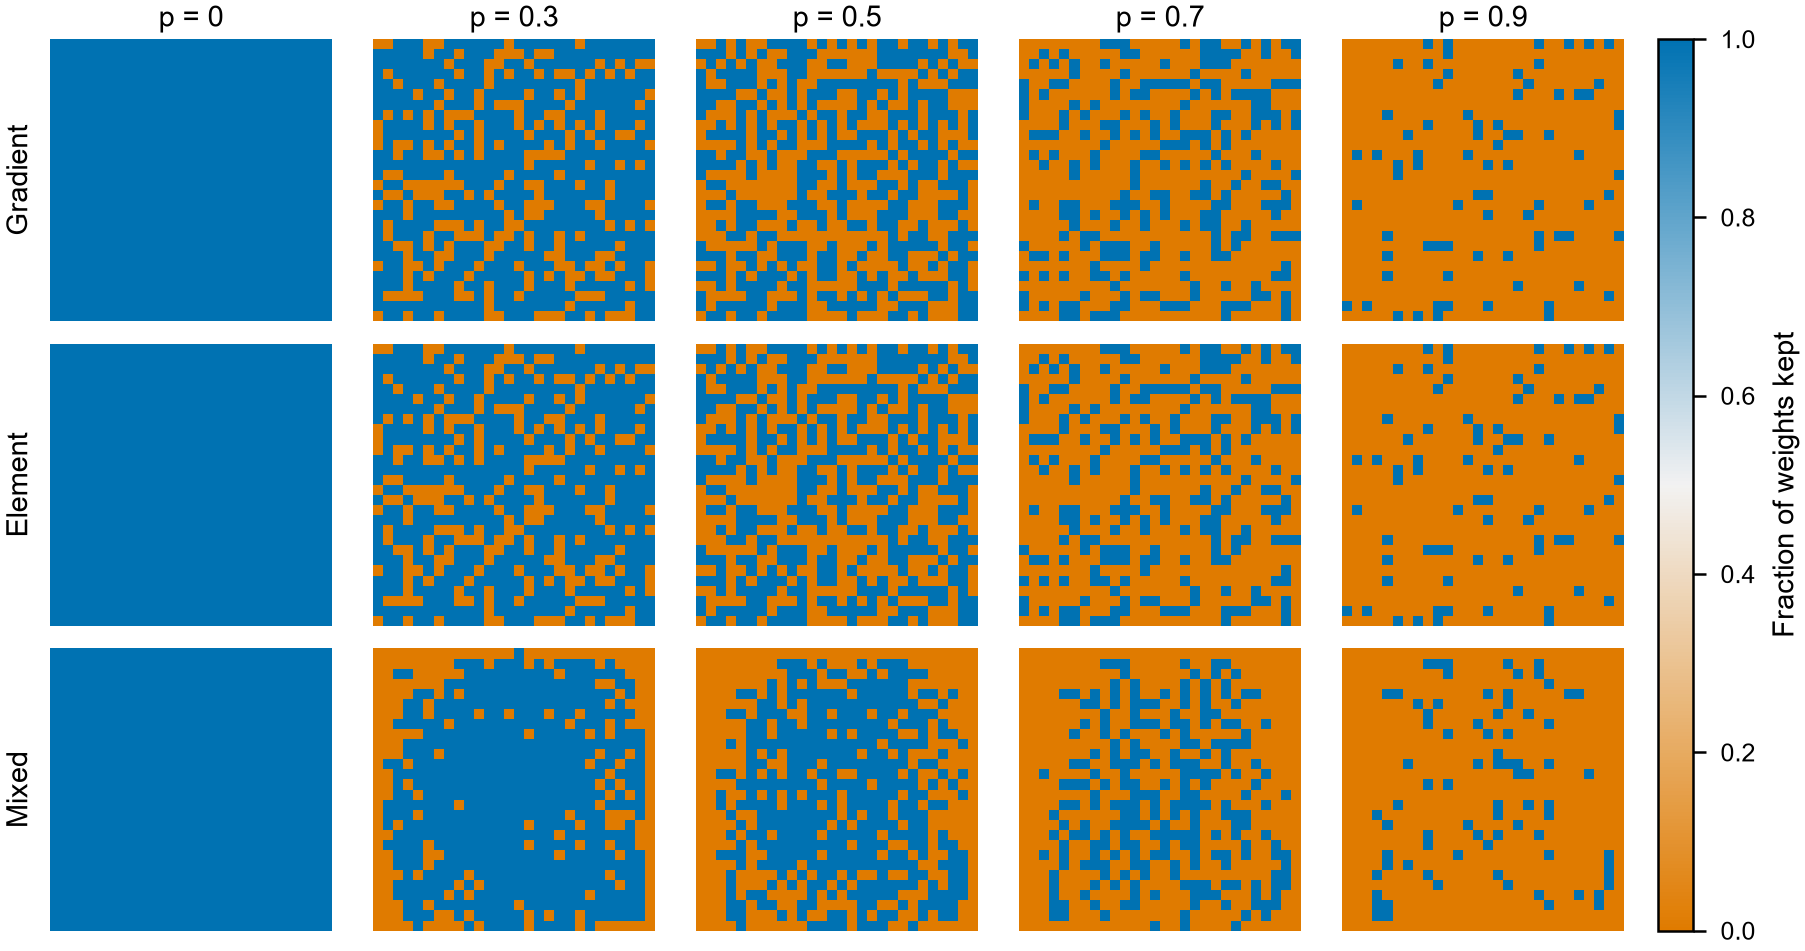

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\masks_filter0.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\masks_filter0.png


In [7]:
plot_mask_grid(KEPT_F, f"masks_filter{FILTER}")

## 4. Effet de la dégradation sur les données

Ce que voit la première couche : l'entrée normalisée multipliée par la part des poids gardés à chaque pixel, canal par canal (`IMAGE_MASK = "all"` : moyenne sur les filtres ; `"filter"` : masque du filtre `FILTER`). Un pixel retiré vaut 0 après normalisation, c'est-à-dire **la couleur moyenne du dataset** une fois l'image dénormalisée pour l'affichage : c'est exactement ce que reçoit le réseau. Signaux : le fond montre la part des poids gardés à chaque instant (bleu = gardé, orange = retiré). Lignes = méthodes, colonnes = *p*. Seulement pour la couche qui voit l'entrée (convolution 0).

Exemple 3 (classe 0)


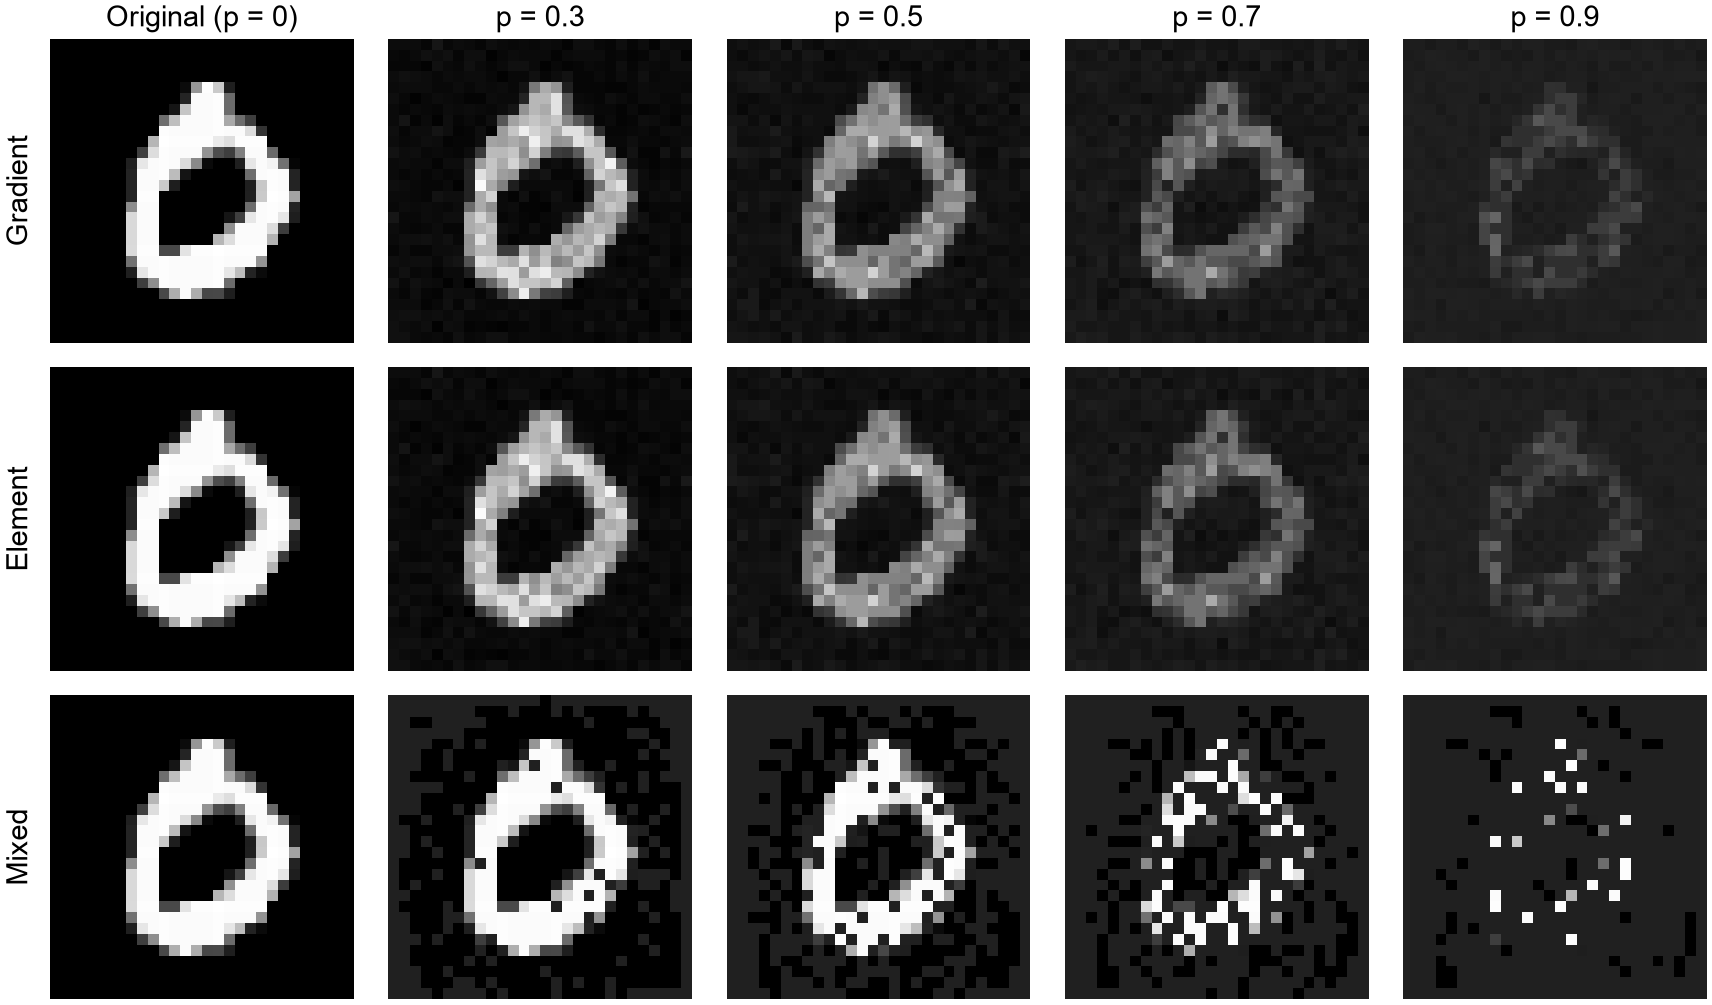

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example3_all.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example3_all.png
Exemple 2 (classe 1)


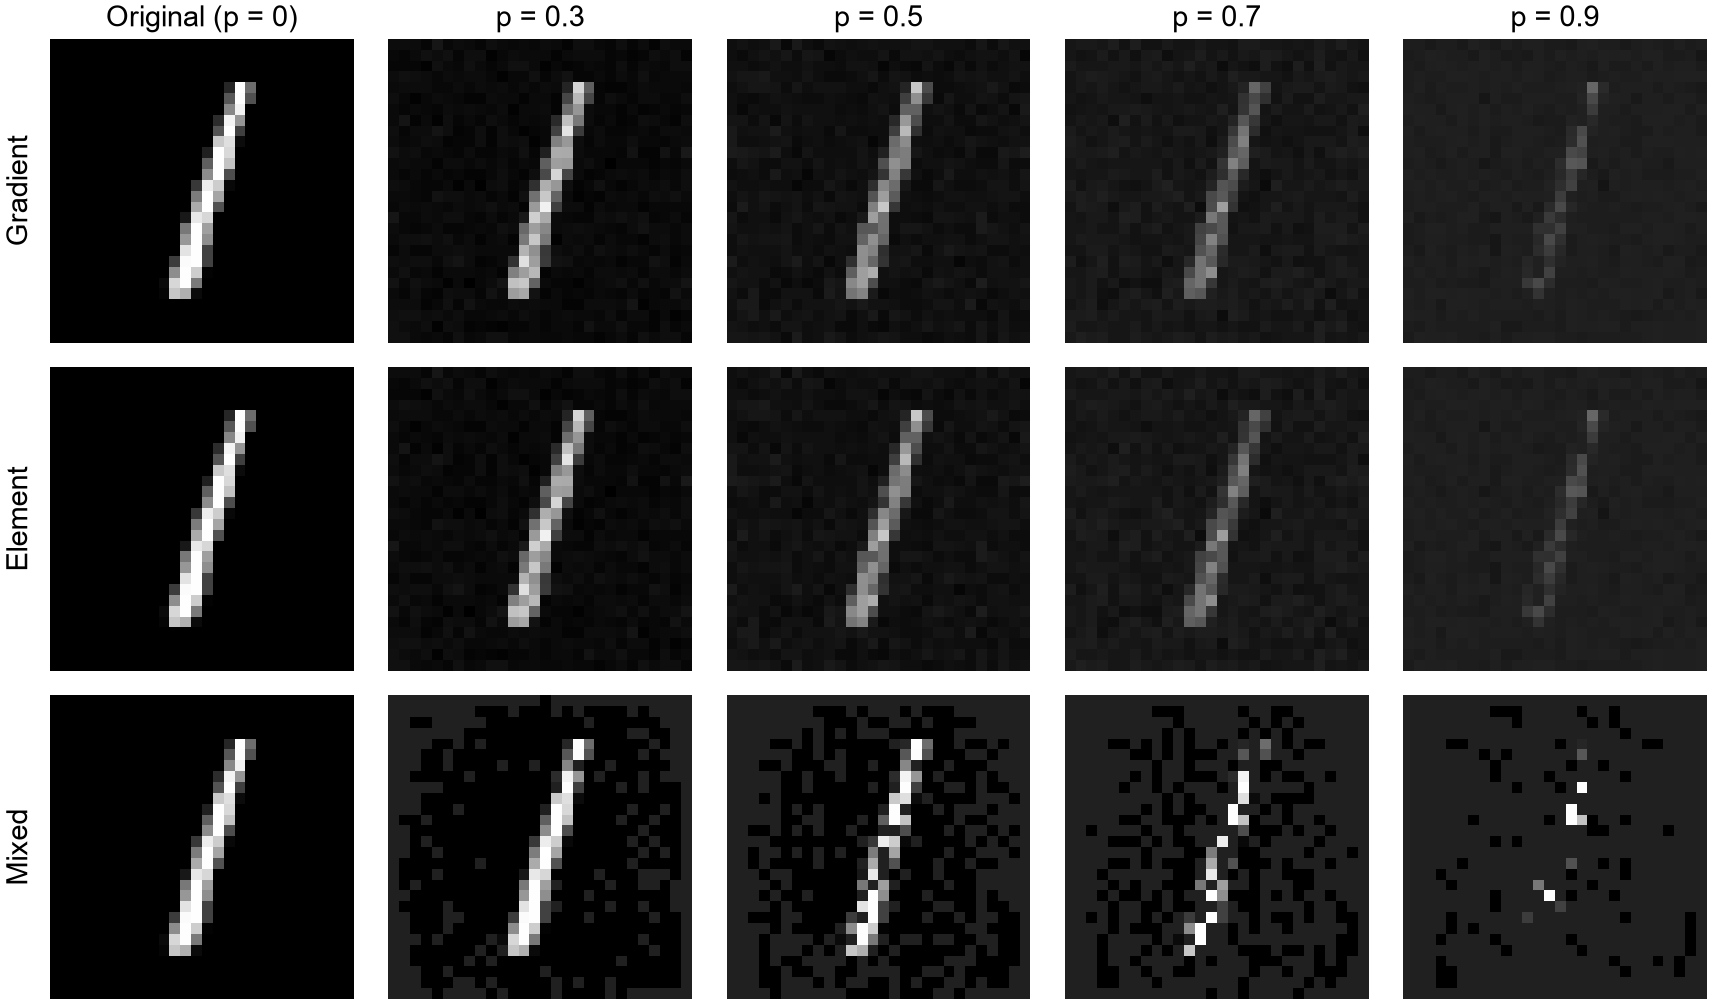

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example2_all.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example2_all.png
Exemple 1 (classe 2)


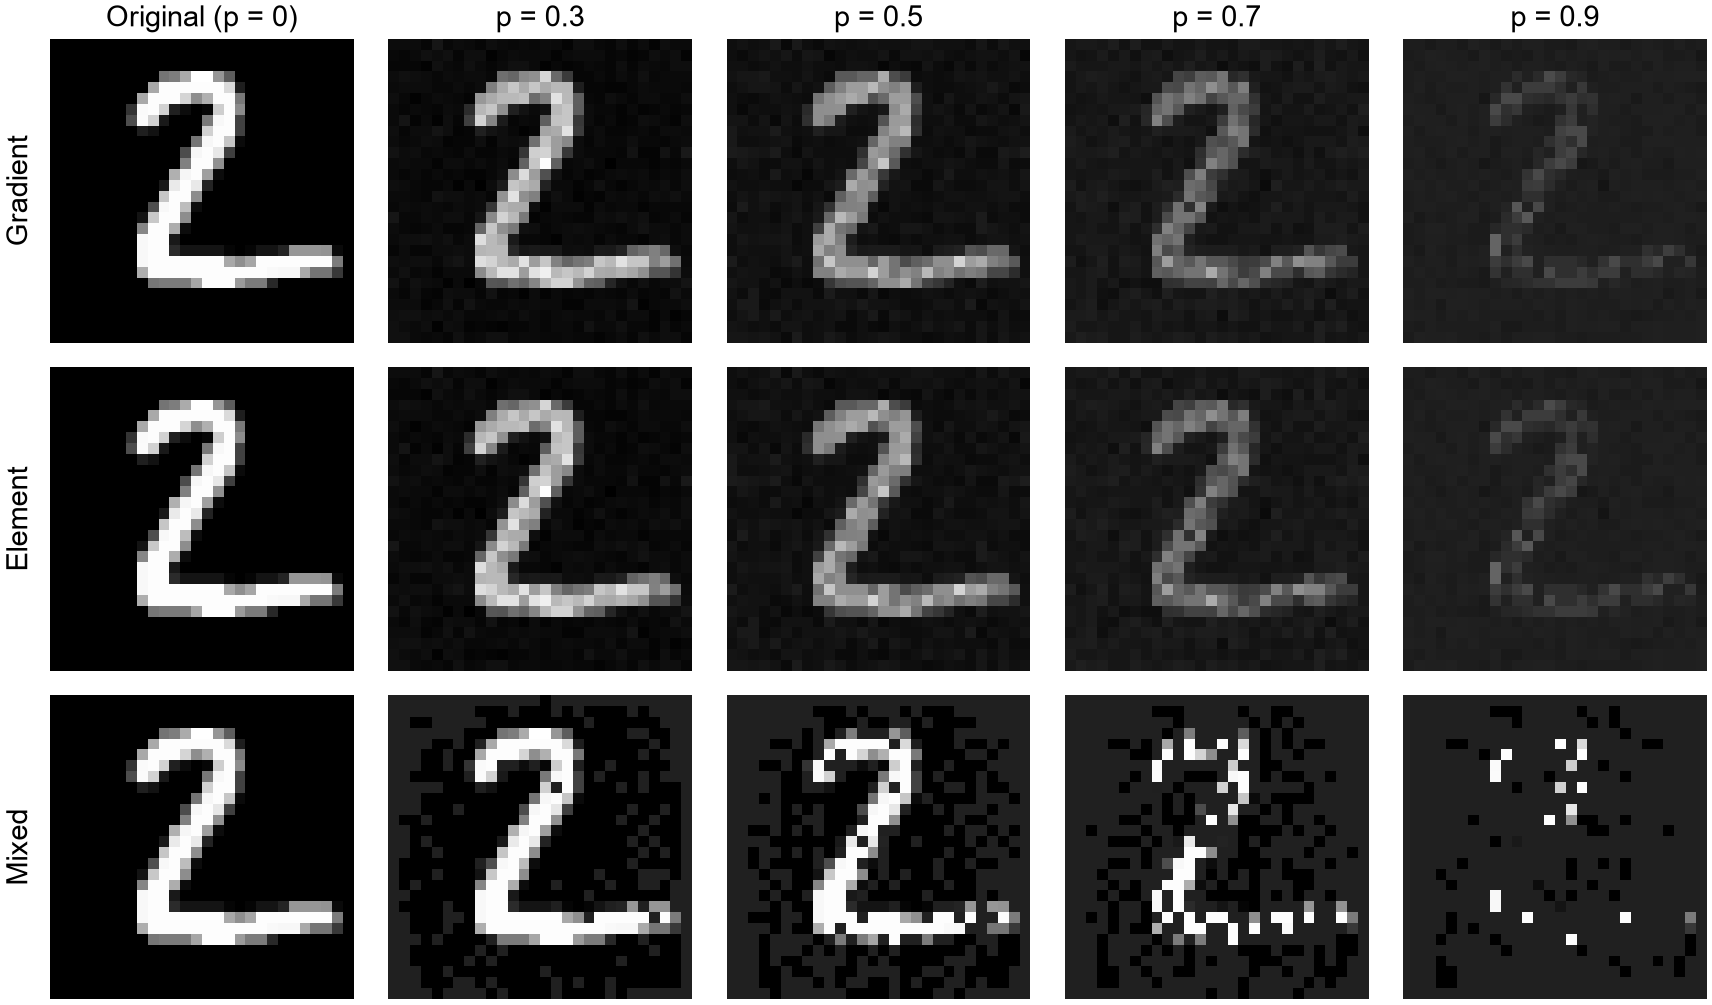

  -> ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example1_all.pdf, ..\runs\mnist_spectral_resnet20_20261103_170107_x5\analyse_lambda_in\spec_cnn2d\data_example1_all.png


In [8]:
def denorm(x):
    return x * std + mean


def seen(x, k):
    """Entrée normalisée x (H, W, C) vue à travers la part gardée k (Cg, H, W) : dénormalisée pour l'affichage,
    sur l'échelle de l'image d'origine (même contraste pour toutes les colonnes)."""
    k = np.moveaxis(k, 0, -1) if k.shape[0] == x.shape[-1] else k.mean(0)[..., None]
    ref = denorm(x)
    lo_, hi_ = (0.0, 1.0) if ref.min() >= 0 and ref.max() <= 1 else (ref.min(), ref.max())
    img = np.clip((denorm(x * k) - lo_) / (hi_ - lo_ + 1e-12), 0, 1)
    return img[..., 0] if img.shape[-1] == 1 else img


if conv_index != 0:
    print("La couche montrée n'est pas la première : ses entrées sont des cartes internes, pas les données.")
else:
    source = KEPT if IMAGE_MASK == "all" else KEPT_F
    if EXAMPLE_INDICES is None:
        classes = [k for k in range(info.num_classes) if (y_test == k).any()][:N_EXAMPLES]
        EXAMPLE_INDICES = [int(np.where(y_test == k)[0][0]) for k in classes]
    n = len(METHODS)
    for idx in EXAMPLE_INDICES:
        x = x_test[idx]
        if SIGNAL:
            cols = len(P_COLS)
            fig, axes = figure(17 * n + 6, n, cols, width_mm=WIDTH_MM, sharex=True, sharey=True,
                               squeeze=False, gridspec_kw={"wspace": 0.06, "hspace": 0.1})
            xs = denorm(x)
            lo_, hi_ = xs.min() - 0.05 * np.ptp(xs), xs.max() + 0.05 * np.ptp(xs)
            for i, m in enumerate(METHODS):
                for j, p in enumerate(P_COLS):
                    a = axes[i, j]
                    k = pick(source[m][p]).mean(0)
                    a.imshow(k[None], extent=[-0.5, len(k) - 0.5, lo_, hi_], aspect="auto",
                             cmap=KEPT_CMAP, vmin=0, vmax=1, alpha=0.45, interpolation="nearest")
                    for ch in range(xs.shape[1]):
                        a.plot(xs[:, ch], lw=0.7, color="black" if ch == 0 else plt.cm.Greys(0.4 + 0.5 * ch / xs.shape[1]))
                    a.set_ylim(lo_, hi_)
                    a.set_xlim(-0.5, len(k) - 0.5)
                    if i == 0:
                        a.set_title(f"p = {p:g}", fontsize=style.font_size, pad=3)
                    if j == 0:
                        a.set_ylabel(METHOD_LABELS[m])
                    else:
                        a.tick_params(labelleft=False)
            fig.supxlabel("Time step", fontsize=style.font_size, y=-0.03)
        else:
            # colonne "Original" seulement si p = 0 n'est pas déjà montré (à p = 0, rien n'est retiré)
            ps = P_COLS if 0.0 in P_COLS else [0.0] + P_COLS
            cols = len(ps)
            fig, axes = figure(WIDTH_MM / (cols + 0.2) * n, n, cols, width_mm=WIDTH_MM, squeeze=False,
                               gridspec_kw={"wspace": 0.05, "hspace": 0.08})
            gray = "gray" if C == 1 else None
            for i, m in enumerate(METHODS):
                for j, p in enumerate(ps):
                    a = axes[i, j]
                    k = np.ones((1,) + x.shape[:2]) if p == 0.0 else pick(source[m][p])
                    a.imshow(seen(x, k), cmap=gray, vmin=0, vmax=1, interpolation="nearest")
                    clean(a)
                    if i == 0:
                        a.set_title("Original (p = 0)" if p == 0.0 else f"p = {p:g}", fontsize=style.font_size, pad=3)
                    if j == 0:
                        a.set_ylabel(METHOD_LABELS[m])
        print(f"Exemple {idx} (classe {class_names[y_test[idx]]})")
        publish(fig, f"data_example{idx}_{IMAGE_MASK}")

## 5. Précision du modèle élagué : les trois méthodes sur une même figure

Pour chaque run, chaque méthode et chaque *p* : masques appliqués aux valeurs d'origine, puis évaluation sur le test du run, comme `pruning.py --mode pre`. Courbe = médiane des runs, bande = quantiles 5 et 95 %, pointillés = hasard. Chaque modèle est remis à ses valeurs entraînées après chaque méthode.

In [ ]:
ROWS = []
if EVALUATE:
    with tf.device(DEVICE):
        for r, agent in enumerate(agents):
            for m in METHODS:
                original, reports = masks_for(agent, P_VALUES, TARGETS, "lambda_in", m, CRITERION,
                                              INCLUDE_PADDING)
                for p, rep in reports.items():
                    acc, loss = evaluate_pruned(agent, rep, original, test_sets[r])
                    ROWS.append({"run": RUN_NAMES[r], "seed": SEEDS[r], "method": m, "p": p,
                                 "fraction_pruned": rep.fraction, "test_accuracy": acc, "test_loss": loss})
                assign_spectral_weights(agent, original, "lambda_in", verbose=False)  # retour au modèle entraîné
            print(f"{RUN_NAMES[r]} évalué")

    acc = {m: [[row["test_accuracy"] for row in ROWS if row["run"] == run and row["method"] == m]
               for run in RUN_NAMES] for m in METHODS}
    fig, ax = figure(60, width_mm=89)
    for i, m in enumerate(METHODS):
        band(ax, np.array(P_VALUES), acc[m], style.color(i), METHOD_LABELS[m], style.marker(i))
    ax.axhline(1 / info.num_classes, color="#8c8c8c", lw=0.6, ls="--", zorder=0)
    ax.set_xlabel("Pruning ratio p")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1.02)
    ax.set_xlim(min(P_VALUES) - 0.02, max(P_VALUES) + 0.02)
    ax.legend(loc="lower left", handlelength=1.8)
    publish(fig, "accuracy_vs_p_methods")
    if Cg == 1 and {"gradient", "element"} <= set(METHODS):
        print("Une seule voie d'entrée par filtre : gradient et element donnent les mêmes masques (courbes superposées).")

    print(f"\n{'p':>5} | " + " | ".join(f"{METHOD_LABELS[m]:>17}" for m in METHODS) + "   (médiane [q5, q95])")
    for k, p in enumerate(P_VALUES):
        cells_ = []
        for m in METHODS:
            v = np.array([a[k] for a in acc[m]])
            cells_.append(f"{np.median(v):.3f} [{np.quantile(v, .05):.3f}, {np.quantile(v, .95):.3f}]")
        print(f"{p:>5.2f} | " + " | ".join(f"{c:>17}" for c in cells_))

seed42 évalué


## 6. Sauvegarde des données

`results.csv` (une ligne par run, méthode et *p*), `summary.csv` (médiane et quantiles par méthode et *p*) et `settings.json`, à côté des figures.

In [ ]:
if ROWS:
    with open(os.path.join(OUT_DIR, "results.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(ROWS[0]))
        w.writeheader(); w.writerows(ROWS)
    with open(os.path.join(OUT_DIR, "summary.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["method", "p", "n", "fraction_pruned", "median", "mean", "std", "q05", "q95"])
        for m in METHODS:
            for p in P_VALUES:
                rows = [row for row in ROWS if row["method"] == m and row["p"] == p]
                v = np.array([row["test_accuracy"] for row in rows])
                w.writerow([m, p, len(v), np.median([row["fraction_pruned"] for row in rows]), np.median(v),
                            v.mean(), v.std(), np.quantile(v, .05), np.quantile(v, .95)])
settings = {"group": GROUP_DIR, "runs": RUN_NAMES, "seeds": SEEDS, "layer": layer.name,
            "conv_index": conv_index, "pruned_layers": TARGET_NAMES, "filter": FILTER, "methods": METHODS,
            "p": P_VALUES, "criterion": CRITERION, "include_padding": INCLUDE_PADDING,
            "mask_run": None if MASK_RUN is None else RUN_NAMES[MASK_RUN], "image_mask": IMAGE_MASK,
            "examples": EXAMPLE_INDICES, "stat": STAT, "band": BAND}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2, ensure_ascii=False)
print(f"Figures et données dans {OUT_DIR}")
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)